# Tutorial 0 — PyTorch: From Images to a Learning Program

Our project will become a handwritten-digit recognizer. In this tutorial, we will learn the PyTorch basic using a small task as an example: **is this image a star or a heart?**.

By the end, you should be able to do the followings:

1. Store images and their correct labels.
2. Run a model to produce class scores.
3. Measure the error and update the model.
4. Check predictions on separate examples.

**Your route through this notebook**

| Sections | Focus |
| --- | --- |
| 1–4 | basic tensor operations |
| 5–10 | Prepare the input, build a model, and make one update |
| 11–13 | Check progress, repeat training, and save the result model |

Run the cells in order. It is able to begin with only understanding of python basics.

## 0. An image is a grid of numbers

A **pixel** is one position in an image. For an 8-bit grayscale image, its value represents brightness: **0 is black, 255 is white**, and values between them are gray. An example below:

![A two-row grayscale image beside its pixel values; the gray pixel at row 0, column 1 is highlighted in both.](assets/tutorial_0_pixels.png)

A grayscale image has one brightness **channel**. A color image can have three channels: red, green, and blue. In this tutorial We will use grayscale images.

## 2. What is PyTorch?

**Why learn it?**

[PyTorch](https://pytorch.org/) is a Python library for building and training machine-learning and deep-learning models. It is widely used in research and industry. Learning it can help you understand model code and build your own projects.

**What does it simplify?**

PyTorch helps us process input data, build models from ready-made components, and train them. It calculates model outputs, measures prediction errors, and works out how changes inside the model affect those errors. 

Its training tools use this information to improve the model, saving us from rewriting these calculations ourselves.

**What would doing this from scratch involve?**

With only Python or NumPy, you would write each layer's calculations yourself. You would also work out and code how to update the parameters in details. This means more code to write and check, spending weeks on exsited works. PyTorch provides these tools so we can focus on designing and training our model.

## 3. Setup 

A **virtual environment** keeps this project's Python libraries in a `.venv` folder. A notebook's **kernel** is the Python process that runs its code cells.

You need Python installed and the **Python** and **Jupyter** extensions enabled in VS Code. Python 3.12 is recommended. Installing packages needs an internet connection and may take several minutes. The lesson runs on CPU.


### 3.1 terminal setup, then notebook installation

These terminal commands are for **macOS or Linux**. Skip this option if you completed Option A.

**Step 1 — open the project and its terminal**

1. In VS Code, choose **File → Open Folder**. Open the repository folder.
2. Choose **Terminal → New Terminal**. A terminal panel opens at the bottom of VS Code.
3. Type the following commands **in that terminal**, pressing Enter after each line:

```bash
pwd
ls
```

`pwd` prints your current folder. `ls` lists its contents. You should see `number_classifier` in the list. If you are inside that folder instead, enter `cd ..` to move up to the repository root.

**Step 2 — create and activate the environment**

Enter these commands **in the same terminal**, one line at a time:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install ipykernel
```

| Command | What it does |
| --- | --- |
| `python3 -m venv .venv` | Creates the project's virtual environment |
| `source .venv/bin/activate` | Makes this terminal use that environment |
| `python -m pip install ipykernel` | Installs the package needed to run notebook cells |

If `.venv` already contains a working environment, skip the first command and reuse it. After activation, the terminal prompt usually starts with `(.venv)`.

**Step 3 — select the environment in the notebook**

1. Open `number_classifier/tutorial_0_pytorch_basics.ipynb` in the editor.
2. Click **Select Kernel**, or the current kernel name, at the top right.
3. Choose **Select Another Kernel → Python Environments** if needed.
4. Select the project's **.venv** environment. Its Python path should be inside `mli-tutorials/.venv/bin/`.

Activating the terminal does **not** select the notebook kernel. These are separate steps.

**Step 4 — check the selected Python**

**Where:** run the code cell below **in the notebook**, using its left-hand Run button or **Shift+Enter**. The printed path should point inside your project's `.venv` folder.

In [7]:
import sys
print("Notebook Python:", sys.executable)

Notebook Python: /Users/ctx/Desktop/IC/IC4/Machine Learning for Imaging/mli-tutorials/.venv/bin/python


**Step 5 — install the lesson libraries**

**Where:** run the next code cell **in the notebook**, after selecting and checking the kernel.

`%pip` installs packages into the **current notebook kernel's environment**. Here, `torch` is PyTorch; `torchvision` supplies image tools for Tutorial 1; NumPy handles arrays; Matplotlib draws plots.

Run this installation cell once. On later visits, you can skip it.

In [8]:
%pip install torch torchvision numpy matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### 3.2 restart the kernel and check PyTorch

1. After installation, click **Restart** in the notebook toolbar. Confirm that your project's kernel is still selected.
2. Run the import cell below with **Shift+Enter**. A PyTorch version number should appear below it.

**Next time:** reopen the notebook, select the same kernel, and start with this import cell. You do not need to recreate the environment or reinstall the libraries. A kernel restart clears variables; saved outputs do not restore them.

If you see `ModuleNotFoundError: No module named 'torch'`, check the kernel path in Step 4. Select the project's environment and install the packages there.

References: [Python virtual environments](https://docs.python.org/3/library/venv.html), [VS Code kernel selection](https://code.visualstudio.com/docs/datascience/jupyter-kernel-management), [IPython `%pip`](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-pip).

In [9]:
import torch
from torch import nn

torch.manual_seed(42)
print("PyTorch:", torch.__version__)

PyTorch: 2.6.0


## 4. Tensor Basics
To classify a star or a heart, our model must calculate with the image's pixel values. We store those values in a **tensor**, the basic data format used for numerical operations in PyTorch. Almost all data need operate with are represented as tensor in Pytorch.

A tensor is an array of numbers that can have different numbers of dimensions. A list of values is one-dimensional; a grayscale image's rows and columns form a two-dimensional tensor. Its **shape** gives the size of each dimension, also called an **axis**.

We will start with the tiny image from Section 1. `torch.tensor(...)` converts its Python list of pixel values into a tensor.

Axis numbering starts at zero: axis 0 selects rows, and axis 1 selects columns.

In [10]:
pixels = torch.tensor([[0, 128, 255], [255, 128, 0]], dtype=torch.float32) # dtype are number format that stors value.
pixels = pixels / 255
print("Values:", pixels)
print("Shape:", pixels.shape) # two rows and three columns
print("Number type:", pixels.dtype) 

Values: tensor([[0.0000, 0.5020, 1.0000],
        [1.0000, 0.5020, 0.0000]])
Shape: torch.Size([2, 3])
Number type: torch.float32


### 4.1 Give each axis a meaning

Machine learning often needs data with more than two dimensions. For our image task, rows and columns describe each picture, but we also need to represent **channels** and groups of images. A grayscale image has one channel; an RGB image has three. A **batch** is a numbers of images grouped together.

We will use the common PyTorch image format `[B, C, H, W]`. For example, `[16, 1, 28, 28]` describes:

| Axis | Meaning | Size |
| --- | --- | --- |
| 0: B | 16 images forms a batch | 16 |
| 1: C | Channels per image | 1 |
| 2: H | Rows pixels per image | 28 |
| 3: W | Columns pixels per image| 28 |

Our practice tensor `pixels` has shape `[2, 3]`, so it has no channel or batch axis yet. Even a single grayscale image needs these axes to fit the format we will use.

`unsqueeze(dim)` inserts a dimension of size one at position `dim`. Here we call `unsqueeze(0)` twice:

1. Add the channel axis: `[2, 3]` becomes `[1, 2, 3]`.
2. Add the batch axis: `[1, 2, 3]` becomes `[1, 1, 2, 3]`.

The pixel values stay the same. We have described one channel and a batch of one image; we have not created additional images.

In [11]:
image = pixels.unsqueeze(0)
small_batch = image.unsqueeze(0)
print("One image:", image.shape)
print("Batch of one:", small_batch.shape)

One image: torch.Size([1, 2, 3])
Batch of one: torch.Size([1, 1, 2, 3])


### 4.2 Select an image or a pixel

Indices start at zero. `:` means all entries on that axis.

| Expression | Selects | Result |
| --- | --- | --- |
| `pixels[0]` | First row | `[0.0, ~0.502, 1.0]` |
| `pixels[:, 0]` | First column | `[0.0, 1.0]` |
| `pixels[0, 2]` | Row 0, column 2 | `1.0` |

Selecting one image with `images[0]` removes the batch axis. A slice such as `images[0:1]` keeps a batch containing one image. We will use that slice when predicting a single shape.

In [12]:
print("First row:", pixels[0])
print("First column:", pixels[:, 0])
print("One pixel:", pixels[0, 2])
print("Keep one image as a batch:", small_batch[0:1].shape)

First row: tensor([0.0000, 0.5020, 1.0000])
First column: tensor([0., 1.])
One pixel: tensor(1.)
Keep one image as a batch: torch.Size([1, 1, 2, 3])


### 4.3 Flatten an image into a vector

Each grayscale image in our task starts as a two-dimensional grid of pixels. Many machine-learning models, including the **Linear** layer we will use first, expect each input as a **vector**. We therefore need to turn each image into one row of inputs while keeping different images separate. 

`flatten(start_dim=1)` keeps the batch axis and combines the remaining axes. It preserves the pixel values and their order.

![Two images are flattened independently. Each image's two rows become six entries in its own output row, with image membership preserved by color.](assets/tutorial_0_flatten.png)

Blue and orange identify different images. The diagram illustrates a batch of two; the code below uses our batch of one. Pixel values in the diagram are rounded.

In general, `[B, C, H, W]` becomes `[B, C*H*W]`. Plain `flatten()` also merges the batch axis, so use `flatten(1)` to keep each image separate.

In [13]:
flat_pixels = small_batch.flatten(start_dim=1)
print("Values:", flat_pixels)
print("Shape:", flat_pixels.shape)

Values: tensor([[0.0000, 0.5020, 1.0000, 1.0000, 0.5020, 0.0000]])
Shape: torch.Size([1, 6])


## 5. Our task: star or heart?

We now have enough tensor methods to conduct our first task.

in this task, each input will be a **28×28 grayscale image**, with a black star or heart on white. The label is **0 for star** and **1 for heart**.

Run the supplied drawing code to see the two templates. Focus on the images and their tensor shape; the geometry is only data preparation. **The plotted 28×28 pixels are the same resolution the model receives.**

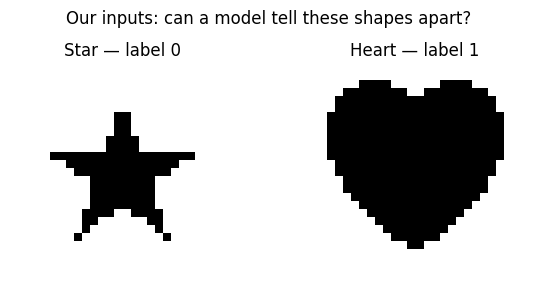

Template shape: torch.Size([2, 1, 28, 28])


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolygonPath

# Draw two shape masks directly on a 28×28 grid.
axis = np.linspace(-1.4, 1.4, 28)
x, y = np.meshgrid(axis, axis[::-1])
angles = np.pi / 2 + np.arange(10) * np.pi / 5
radii = np.where(np.arange(10) % 2 == 0, 1.0, 0.381966)
vertices = np.column_stack((radii * np.cos(angles), radii * np.sin(angles)))
star = PolygonPath(vertices).contains_points(np.column_stack((x.ravel(), y.ravel())))
star = star.reshape(28, 28)
heart = (x**2 + y**2 - 1)**3 - x**2 * y**3 <= 0

# Convert the masks to image tensors: black = 0, white = 1.
templates = torch.tensor(np.stack([~star, ~heart]), dtype=torch.float32).unsqueeze(1)
class_names = ["star", "heart"]
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for label, ax in enumerate(axes):
    ax.imshow(templates[label, 0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"{class_names[label].title()} — label {label}")
    ax.axis("off")
fig.suptitle("Our inputs: can a model tell these shapes apart?")
plt.tight_layout()
plt.show()
print("Template shape:", templates.shape)

### Make examples to learn from and examples to check

To create more repeats of example, we add random noise to the template, 
and these will be the sample used to train the model. We also create a
separate set of examples to check the model's predictions. 

Training: torch.Size([128, 1, 28, 28]) torch.Size([128])
Validation: torch.Size([64, 1, 28, 28]) torch.Size([64])


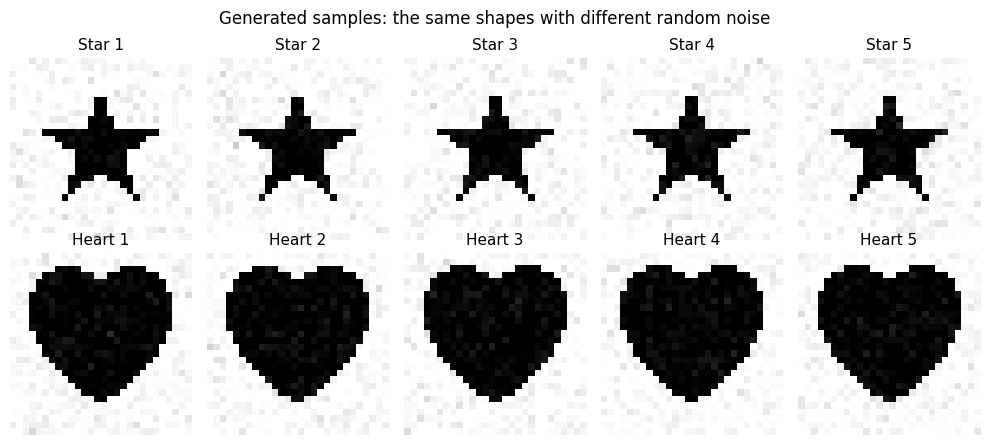

In [15]:
all_images = templates.repeat(96, 1, 1, 1)
all_images = (all_images + 0.05 * torch.randn(all_images.shape)).clamp(0, 1)
all_labels = torch.tensor([0, 1], dtype=torch.long).repeat(96)

train_images, train_labels = all_images[:128], all_labels[:128]
val_images, val_labels = all_images[128:], all_labels[128:]
print("Training:", train_images.shape, train_labels.shape)
print("Validation:", val_images.shape, val_labels.shape)

# Preview actual training samples: five stars and five hearts.
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for label, row_axes in enumerate(axes):
    samples = train_images[train_labels == label][:5]
    for sample_index, ax in enumerate(row_axes):
        ax.imshow(samples[sample_index, 0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{class_names[label].title()} {sample_index + 1}", fontsize=11)
        ax.axis("off")
fig.suptitle("Generated samples: the same shapes with different random noise")
plt.tight_layout()
plt.show()

- **Training data:** the first 128 examples. The model uses their images and labels to update its parameters. The grid above shows five actual training samples from each class.
- **Validation data:** the remaining 64 examples, generated with separate random noise. We use them to check predictions without updating the model.

Both sets contain the same two fixed shapes with different noise. This checks learning on these patterns, not on new shape designs.

## 6. Feed the model a batch at a time

`TensorDataset` pairs each image with its label. `DataLoader` gives us batches of these pairs. With `batch_size=16`, each batch contains sixteen examples; `shuffle=True` changes their order while keeping each pair together.

![A Dataset stores image-label pairs. DataLoader shuffles pairs and groups sixteen into an images tensor of shape 16 by 1 by 28 by 28 and a labels tensor of shape 16.](assets/tutorial_0_dataloader.png)

The diagram shows a few example pairs. Within the output batch, `images[k]` and `labels[k]` still refer to the same example.

In [16]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(train_images, train_labels)
val_dataset = TensorDataset(val_images, val_labels)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

for images, labels in train_loader:
    print("Image batch:", images.shape)
    print("Label batch:", labels.shape)
    break

Image batch: torch.Size([16, 1, 28, 28])
Label batch: torch.Size([16])


## 7. Build a model that produces two scores

**Input:** a batch of 28×28 grayscale images. `Flatten` turns each image into one row of 784 pixel values.

**Model:** `nn.Linear(784, 2)` has two output **neurons**. Each multiplies the inputs by its own weights, sums the products, and adds its bias. These weights and biases are the parameters training will adjust.

![A 28 by 28 image is flattened into 784 inputs. All inputs connect to both the star neuron and the heart neuron; each output uses its own weights and bias.](assets/tutorial_0_linear_layer.png)


**Output:** each row is `[star score, heart score]`. Class **0 is star**; class **1 is heart**. Choose the larger score:

| Star score | Heart score | Predicted class |
| --- | --- | --- |
| 3.2 | 0.8 | 0: star |
| 0.4 | 2.7 | 1: heart |
| -1.0 | -3.0 | 0: star |

These scores are illustrative, not measured results. A score is not a probability, and a prediction may be wrong.

For worked neuron arithmetic, see Sections 1–2 of [Victor Zhou's introduction](https://victorzhou.com/blog/intro-to-neural-networks/). It adds a sigmoid activation; our linear layer stops at the weighted sum plus bias.

In the code, `nn.Module` is the model's base class. `__init__` creates its parts, `super().__init__()` initializes the base class, and `forward` connects the parts. Calling `model(images)` runs that calculation. For now, you only need to remember the way to write the code, fully understanding of the code need a strong background in Python and PyTorch. you will be more familiar as you continue to use it in the following tutorials.

In [17]:
class ShapeClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten(start_dim=1)
        self.classifier = nn.Linear(784, 2)

    def forward(self, images):
        return self.classifier(self.flatten(images))

model = ShapeClassifier()
example_images = train_images[:2]  # One star and one heart, with noise.
example_labels = train_labels[:2]
logits = model(example_images)
print("Initial scores [star, heart]:")
print(logits)

Initial scores [star, heart]:
tensor([[-0.0115, -0.0088],
        [-0.2341,  0.0060]], grad_fn=<AddmmBackward0>)


## 8. Read the prediction, then measure its error

### 8.1 Which class has the larger score?

The raw scores are called **logits**. `argmax(dim=1)` looks across the class columns in each row and returns the winning class index.

| Illustrative image | Star score | Heart score | Winning index |
| --- | --- | --- | --- |
| Image 0 | 3.2 | 0.8 | 0 |
| Image 1 | 0.4 | 2.7 | 1 |

For this table, `argmax(dim=1)` returns `[0, 1]`: one class index per image.

Below, compare our untrained model's actual predictions with the correct labels. It has not learned from these images yet.

In [18]:
predictions = logits.argmax(dim=1)
print("Predicted labels:", predictions)
print("Correct labels:  ", example_labels)

Predicted labels: tensor([1, 1])
Correct labels:   tensor([0, 1])


### 8.2 How strongly does the model support the correct answer?

A **loss** is a number measuring prediction error; training tries to reduce it. `CrossEntropyLoss` uses both class scores and the correct label. It becomes smaller as the correct class gains more probability.

For a star image with correct label 0:

| Illustrative scores: [star, heart] | Favors | Loss |
| --- | --- | --- |
| `[0.0, 2.0]` | Heart, the wrong class | Higher |
| `[2.0, 0.0]` | Star, the correct class | Lower |

Give this loss the **raw logits**, with integer labels. It handles the probability calculation internally. The result is the average loss over the examples. `.item()` reads a single tensor value as a Python number for printing.

In [19]:
loss_fn = nn.CrossEntropyLoss()
loss = loss_fn(logits, example_labels)
print("Loss on our two examples:", loss.item())

Loss on our two examples: 0.63739413022995


## 9. Find a direction for improving the model

We have an error measurement. A **gradient** tells us how that error changes when a parameter changes slightly. PyTorch tracks the model's calculation and works out these gradients automatically; this feature is called **autograd**.

`loss.backward()` traces the calculation back from the loss and stores parameter gradients in `.grad`. This backward calculation is called **backpropagation**.

The code shows the gradients for our two output biases, in star/heart order. The weights also get gradients. Model parameters are tracked automatically; **their values have not been updated yet**.

In [20]:
loss.backward()
print("Bias gradients [star, heart]:")
print(model.classifier.bias.grad)

Bias gradients [star, heart]:
tensor([-0.0302,  0.0302])


## 10. Make one update and observe the result

An **optimizer** updates parameters using their gradients. We use `SGD` (stochastic gradient descent) with a **learning rate** of 0.01, which controls the update size. `model.parameters()` supplies the weights and biases to update.

**Update rule:** new parameter = old parameter − learning rate × gradient.

![A numbered training cycle clears old gradients, computes scores, measures loss, calculates gradients with backward, and updates parameters with optimizer step before the next batch.](assets/tutorial_0_training_update.png)

Gradients accumulate, so we clear the previous calculation first. Notice the separate jobs of `backward()` and `step()`.

Below, we recompute the loss and gradients, make one update, then measure loss again on **the same two images**. A smaller loss shows improvement on these examples; it does not yet tell us how the model handles other images.

In [21]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

optimizer.zero_grad()
logits = model(example_images)
loss = loss_fn(logits, example_labels)
loss_before = loss.item()
loss.backward()
optimizer.step()

loss_after = loss_fn(model(example_images), example_labels).item()
print(f"Same two images: loss {loss_before:.3f} -> {loss_after:.3f}")

Same two images: loss 0.637 -> 0.463


## 11. Check predictions without updating the model

We now check the **validation images**, which have not been used for parameter updates. **Accuracy** is the fraction of predictions matching their labels.

| Example | Prediction | Correct label | Match? |
| --- | --- | --- | --- |
| 0 | 0 | 0 | True |
| 1 | 0 | 1 | False |
| 2 | 1 | 1 | True |
| 3 | 1 | 1 | True |

In this illustration, `(predictions == labels).sum().item()` counts **3 correct**. Accuracy is **3 / 4 = 75%**.

| Call | Purpose |
| --- | --- |
| `model.train()` | Select training behavior for layers |
| `model.eval()` | Select evaluation behavior for layers |
| `torch.no_grad()` | Skip gradient tracking inside its block |

Our current layers behave the same in both modes; later CNN layers may differ. The mode switches do not perform training or replace `no_grad()`.

The loop below counts correct predictions across batches without updating parameters. `len(val_dataset)` is the number of validation images.

In [22]:
model.eval()
correct = 0
with torch.no_grad():
    for images, labels in val_loader:
        predictions = model(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()

val_accuracy = correct / len(val_dataset)
print(f"Validation accuracy after one update: {val_accuracy:.1%}")

Validation accuracy after one update: 53.1%


## 12. Repeat the same learning steps

One **epoch** is one pass through the training dataset. With 128 images and batches of 16, each epoch makes eight updates. We continue with **the same model and optimizer** from Section 10.

![Within one epoch, 128 training images drive eight parameter updates. The same updated model then predicts 64 separate validation images to measure accuracy without further updates.](assets/tutorial_0_train_validation.png)

Follow the two rows: training changes the model; validation only checks it. The next cell repeats this process for six epochs.

For the training report, multiply each batch's average loss by its image count, add those totals, and divide by the total image count. This gives each image equal weight, even if a final batch is shorter.

The printed **loss** is measured as training proceeds; **validation accuracy** is measured after each epoch. Look for decreasing loss and improving accuracy.

In [23]:
for epoch in range(6):
    model.train()
    train_loss_sum = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * labels.shape[0]

    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()

    train_loss = train_loss_sum / len(train_dataset)
    val_accuracy = correct / len(val_dataset)
    print(f"Epoch {epoch + 1}: loss={train_loss:.3f}, validation accuracy={val_accuracy:.1%}")

Epoch 1: loss=0.241, validation accuracy=100.0%
Epoch 2: loss=0.081, validation accuracy=100.0%
Epoch 3: loss=0.050, validation accuracy=100.0%
Epoch 4: loss=0.037, validation accuracy=100.0%
Epoch 5: loss=0.028, validation accuracy=100.0%
Epoch 6: loss=0.023, validation accuracy=100.0%


### Use the trained model on one image

Using a model to make predictions is called **inference**. Follow the three steps in the code:

1. Slice `val_images[0:1]` to keep a batch of one image, shape `[1, 1, 28, 28]`.
2. Run the model to obtain `[star score, heart score]`.
3. Use `argmax` for the winning index and `class_names[index]` for its name.

The examples use two fixed shapes with different noise, so high accuracy is expected. It demonstrates this learning workflow; it does not establish performance on shapes with new positions or sizes, or on handwriting.

In [24]:
single_image = val_images[0:1]
model.eval()
with torch.no_grad():
    single_scores = model(single_image)
    predicted_class = single_scores.argmax(dim=1).item()

print("Scores [star, heart]:", single_scores)
print("Predicted:", class_names[predicted_class])
print("Actual:", class_names[val_labels[0].item()])

Scores [star, heart]: tensor([[ 2.0086, -2.0477]])
Predicted: star
Actual: star


## 13. Save the learned parameters

`state_dict()` collects a model's learned tensor state. To reuse the result:

1. **Save:** write `model.state_dict()` to a file with `torch.save`.
2. **Recreate:** construct a new `ShapeClassifier` with the same structure.
3. **Restore:** read the file with `torch.load` and apply it with `load_state_dict`.

`Path` handles the output folder. `weights_only=True` selects loading for tensor state; `map_location="cpu"` loads it on CPU. The restored model should produce the same scores for the same image.

In [25]:
from pathlib import Path

artifact_dir = Path("artifacts")
artifact_dir.mkdir(exist_ok=True)
weights_path = artifact_dir / "tutorial_0_shapes.pt"
torch.save(model.state_dict(), weights_path)

restored_model = ShapeClassifier()
restored_model.load_state_dict(torch.load(weights_path, weights_only=True, map_location="cpu"))
restored_model.eval()
with torch.no_grad():
    restored_scores = restored_model(single_image)
print("Restored scores [star, heart]:", restored_scores)

Restored scores [star, heart]: tensor([[ 2.0086, -2.0477]])


## Optional reference — return when you need it

You can move on to Tutorial 1 now. These are short reminders of other tensor tools, not additional steps in the shape-classification task.

### Rearrange entries: reshape and permute

`reshape` regroups entries in their current logical order; `permute` swaps the order of axes. Both keep the numbers, but the resulting positions differ.

![The original matrix contains rows one two three and four five six. Reshape groups consecutive entries into three rows of two, while permute swaps the row and column axes. Each value keeps its color across the arrangements.](assets/tutorial_0_reshape_permute.png)

Both results start from the original matrix. Track a number's color to see where it goes: the two results have the same shape but different arrangements.

`reshape(2, -1)` asks PyTorch to infer the second size. To convert image axes `[H, W, C]` to `[C, H, W]`, use `permute(2, 0, 1)`.

### Views and copies

The shape method `view(...)` shares data and requires a compatible memory arrangement. `reshape` can share data or copy when needed. `clone()` guarantees independent data.

| Operation | Effect |
| --- | --- |
| `b = a` | Another name for the same tensor |
| `b = a.view(3, 2)` | A reshaped view sharing a's data |
| `b = a.clone()` | Independent data with equal starting values |
| `b.copy_(a)` | Write a's values into the existing tensor b |

A trailing underscore, as in `copy_` or `add_`, marks an operation that modifies its target in place.

### Combine tensors or remove a length-one axis

`stack` creates a new axis to keep inputs separate. `cat` joins them along an existing axis. Both examples below start with `a = [1, 2]` and `b = [3, 4]`.

![Stack turns two vectors into two separate rows with shape two by two, while cat joins the same vectors into one longer vector with shape four.](assets/tutorial_0_stack_cat.png)

The blue entries come from a; the orange entries come from b. `squeeze(0)` removes axis 0 if its size is one: `[1, H, W]` becomes `[H, W]`.

### Average along an axis

`mean(dim=1)` averages the columns within each row. `mean(dim=0)` averages the rows within each column.

![For matrix rows one two and three four, averaging each row produces one point five and three point five. Averaging each column produces two and three. Colors identify entries grouped in each average.](assets/tutorial_0_mean_axes.png)

Follow the colored groups: each group becomes one output number. For example, averaging the first column gives `(1 + 3) / 2 = 2.0`.

### Display probabilities

`softmax(dim=1)` converts each row of scores into probabilities summing to one.

| Class | Raw score | Probability after softmax |
| --- | --- | --- |
| Star | 2.0 | Approximately 0.95 |
| Heart | -1.0 | Approximately 0.05 |

Keep **raw scores** as the input to `CrossEntropyLoss`.

### Recognize device and conversion code

A supported GPU can accelerate larger models. `.to(device)` places a tensor or model on the selected device; model parameters and inputs must be compatible. This lesson uses CPU throughout.

When you see `tensor.detach().cpu().numpy()`, read the calls from left to right:

| Call | Purpose |
| --- | --- |
| `.detach()` | Disconnect from gradient tracking |
| `.cpu()` | Move to CPU if needed |
| `.numpy()` | Obtain an array for NumPy-based tools |

`detach()` can share data; it is not an independent copy. `detach().clone()` makes an independent snapshot without a gradient connection.

**Official references:** [Tensors](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html), [Data loading](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html), [Autograd](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html), [Optimization](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).